# PoI Detection in the Enron Corpus
## Load Datasets

In [26]:
import pandas as pd

# Load POI dataset
poi_data = pd.read_pickle('poi_dataset.pkl')

# Load structured Enron email dataset
emails = pd.read_csv('enron_mails.csv')

## Prepare PoI Data

In [27]:
data = []

for person, features in poi_data.items():
    # Skips the TOTAL line
    if person == 'TOTAL':
        continue

    # Only include features relevant for this project
    data.append({
        'person': person,
        'email': features.get('email_address'),
        'poi': features.get('poi')
    })

# Add data to a dataframe
poi_dataframe = pd.DataFrame(data)

# Some email addresses include the string "NaN", convert this to actual missing values
poi_dataframe['email'] = poi_dataframe['email'].replace('NaN', pd.NA)


## Matching People to Email Communication

In [28]:
import re

# Extracts email addresses for emails with multiple recipients
def extract_emails(value):
    if pd.isna(value):
        return []
    
    return re.findall(
        r"[a-z0-9\.\-+_]+@[a-z0-9\.\-+_]+\.[a-z]+",
        str(value)
    )

emails['to_addresses'] = emails['To'].apply(extract_emails)

# Check whether each person in the PoI data is found in the Enron emails

all_recipients = emails['to_addresses'].explode()

poi_dataframe['found_in_communication'] = (
    poi_dataframe['email'].notna() &
    (
        poi_dataframe['email'].isin(
            emails['From'].dropna().unique()
        ) |
        poi_dataframe['email'].isin(
            all_recipients.dropna().unique()
        )
    )
)

# Keep only people who appear in the Enron dataset
matched_people = poi_dataframe[
    poi_dataframe['found_in_communication']
].copy()


## Communication Features

### Emails Sent

In [29]:

# Counts the number of sent emails for each person
sent_counts = emails['From'].value_counts()

matched_people['emails_sent'] = (
    matched_people['email']
    .map(sent_counts)
    .fillna(0)
)

### Emails Received

In [30]:

# Counts the number of emails received for each person
received_counts = all_recipients.value_counts()

matched_people['emails_received'] = (
    matched_people['email']
    .map(received_counts)
    .fillna(0)
)

### Unique Contacts

In [31]:

# Find sender and recipient connections
edges = emails[
    ['From', 'to_addresses']
].explode('to_addresses').copy()

edges = edges.dropna(
    subset=['From', 'to_addresses']
)

edges['From'] = edges['From'].str.lower()
edges['to_addresses'] = edges['to_addresses'].str.lower()

# Counts the number of unique people sent emails to
unique_contacts_sent = (
    edges.groupby('From')['to_addresses']
    .nunique()
)

matched_people['unique_contacts_sent'] = (
    matched_people['email']
    .str.lower()
    .map(unique_contacts_sent)
    .fillna(0)
)

# Counts the number of unique people received emails from
unique_contacts_received = (
    edges.groupby('to_addresses')['From']
    .nunique()
)

matched_people['unique_contacts_received'] = (
    matched_people['email']
    .str.lower()
    .map(unique_contacts_received)
    .fillna(0)
)

### Check for Communication Features

In [32]:
matched_people[
    [
        'emails_sent',
        'emails_received',
        'unique_contacts_sent',
        'unique_contacts_received'
    ]
].describe()

,emails_sent,emails_received,unique_contacts_sent,unique_contacts_received
count,111.000000,111.000000,111.000000,111.000000
mean,472.378378,1678.531532,100.378378,134.018018
std,1638.195121,2390.782975,203.116807,153.760852
min,0.000000,57.000000,0.000000,4.000000
25%,12.000000,289.000000,5.000000,36.500000
50%,29.000000,865.000000,23.000000,78.000000
75%,78.500000,2271.000000,80.500000,174.000000
max,14368.000000,15149.000000,1250.000000,763.000000


## Temporal Features

In [33]:
# Date field also includes weekday, time and timezone, extract them separately
emails['Date'] = pd.to_datetime(
    emails['Date'],
    errors='coerce',
    utc=True
).dt.tz_convert('America/Chicago') 

emails['date_only'] = emails['Date'].dt.date
emails['local_hour'] = emails['Date'].dt.hour
emails['weekday'] = emails['Date'].dt.day_name()

# Prepare data for calculating features, keeping rows with a sender and recorded hour
sent_emails = emails.dropna(
    subset=['From', 'local_hour']
).copy()

# Convert sender to lowercase
sent_emails['From'] = sent_emails['From'].str.lower()

C:\Users\maren\AppData\Local\Temp\ipykernel_36480\1879195958.py:2: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  emails['Date'] = pd.to_datetime(


### Active Days

In [34]:
# Counts the number of active days, being days when they sent an email
active_days = (
    sent_emails.groupby('From')['date_only']
    .nunique()
)

matched_people['active_days'] = (
    matched_people['email']
    .str.lower()
    .map(active_days)
    .fillna(0)
)

### Weekend Rate

In [35]:
# Identifies emails sent during the weekend
sent_emails['during_weekend'] = (
    sent_emails['weekday'].isin(['Saturday', 'Sunday'])
)

# Calculates the proportion of all emails sent during the weekend
weekend_rate = (
    sent_emails.groupby('From')['during_weekend']
    .mean()
)

matched_people['weekend_rate'] = (
    matched_people['email']
    .str.lower()
    .map(weekend_rate)
)

### After Hours Rate

In [36]:
# Identifies emails sent before 7 and after 18
sent_emails['after_hours'] = (
    (sent_emails['local_hour'] < 7) |
    (sent_emails['local_hour'] >= 18)
)

# Calculates the proportion of all emails sent after hours
after_hours_rate = (
    sent_emails.groupby('From')['after_hours']
    .mean()
)

matched_people['after_hours_rate'] = (
    matched_people['email']
    .str.lower()
    .map(after_hours_rate)
)

### Check for Temporal Features

In [37]:
matched_people[
    [
        'active_days',
        'weekend_rate',
        'after_hours_rate'
    ]
].describe()

,active_days,weekend_rate,after_hours_rate
count,111.000000,103.000000,103.000000
mean,46.243243,0.046391,0.394952
std,78.307113,0.086347,0.251670
min,0.000000,0.000000,0.000000
25%,5.500000,0.000000,0.217806
50%,12.000000,0.000000,0.388889
75%,34.000000,0.060529,0.527635
max,346.000000,0.536585,1.000000


## Email Text Profile Preparation

In [38]:
# Normalise sender email addresses
emails['From'] = emails['From'].str.lower().str.strip()

# Combines emails from sender to make a text profile
def combine_emails(email_bodies):
    return " ".join(email_bodies.dropna().astype(str))

sender_text_profile = (
    emails.groupby("From")["body"]
    .apply(combine_emails)
)
matched_people["text_profile"] = (
    matched_people["email"]
    .str.lower().str.strip()
    .map(sender_text_profile)
    .fillna("")
)

## Prepare Dataset

In [39]:
import numpy as np

# Keep only people with a text profile
data = matched_people[
    matched_people["text_profile"] != ""
].copy()

# Reset row numbers
data = data.reset_index(drop=True)

# Extract the labels identifying PoIs and find their positions
y_all = data["poi"].astype(int).values
normal_indexes = np.where(y_all == 0)[0]
poi_indexes = np.where(y_all == 1)[0]

## Metadata Feature Log Transformation

In [40]:
# Identify the metadata input features
metadata_features = [
    'emails_sent',
    'emails_received',
    'unique_contacts_sent',
    'unique_contacts_received',
    'active_days',
    'weekend_rate',
    'after_hours_rate'
]

X_metadata = data[
    metadata_features
].copy()

# Uses log transformation on count features to reduce effect of large count values
log_features = [
    'emails_sent',
    'emails_received',
    'unique_contacts_sent',
    'unique_contacts_received',
    'active_days'
]

X_metadata[log_features] = np.log1p(
    X_metadata[log_features]
)

## Training and Evaluation Splits

In [41]:
from sklearn.model_selection import train_test_split

splits = []

# Create 10 splits to check for consistent results
for seed in range(10):

    # Split the data for normal people into train and test sets
    train_normal, test_normal = train_test_split(
        normal_indexes,
        test_size=0.25,
        random_state=seed
    )

    # Create evaluation set with normal test set and known PoIs
    evaluation_indexes = np.concatenate([
        test_normal,
        poi_indexes
    ])

    splits.append({
        "seed": seed,
        "train_normal": train_normal,
        "evaluation_indexes": evaluation_indexes
    })

## Metadata-Only Model

In [42]:
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.svm import OneClassSVM
from sklearn.metrics import roc_auc_score, average_precision_score

metadata_results = []

for split in splits:

    seed = split["seed"]
    train_normal = split["train_normal"]
    evaluation_indexes= split["evaluation_indexes"]

    # Preprocess metadata using only training data
    imputer = SimpleImputer(strategy="median")
    scaler = StandardScaler()

    # Imputer learns and transforms on training data
    X_train_metadata = imputer.fit_transform(
        X_metadata.iloc[train_normal]
    )

    # Imputer only transforms on evaluation data
    X_evaluation_metadata = imputer.transform(
        X_metadata.iloc[evaluation_indexes]
    )

    # Scaler learns and transforms on training data
    X_train_metadata = scaler.fit_transform(X_train_metadata)

    # Imputer only transforms on evaluation data
    X_evaluation_metadata = scaler.transform(X_evaluation_metadata)

    # Train the One Class SVM model
    model = OneClassSVM(
        kernel="rbf",
        nu=0.10
    )

    # Fit the model
    model.fit(X_train_metadata)

    # Calculate anomaly scores with high score = anomaly
    scores = -model.decision_function(X_evaluation_metadata)

    # Extract labels to evaluate the model
    y_evaluation = y_all[evaluation_indexes]

    # Calculate metrics
    roc_auc = roc_auc_score(y_evaluation, scores)
    average_precision = average_precision_score(y_evaluation, scores)

    # Find the position for the top 10 most anomalous people
    top_10_indexes = np.argsort(scores)[::-1][:10]
    
    # Counts how many of the top 10 are PoIs
    top_10_pois = y_evaluation[top_10_indexes].sum()

    # Calculate metrics for the top 10
    precision_top_10 = top_10_pois / 10
    recall_top_10 = top_10_pois / y_evaluation.sum()

    metadata_results.append({
        "seed": seed,
        "Model": "Metadata",
        "ROC-AUC": roc_auc,
        "Average Precision": average_precision,
        "Precision Top 10": precision_top_10,
        "Recall Top 10": recall_top_10
    })

metadata_results = pd.DataFrame(metadata_results)

metadata_results

,seed,Model,ROC-AUC,Average Precision,Precision Top 10,Recall Top 10
0,0,Metadata,0.518182,0.468010,0.4,0.266667
1,1,Metadata,0.533333,0.458059,0.4,0.266667
2,2,Metadata,0.518182,0.498309,0.4,0.266667
3,3,Metadata,0.545455,0.508670,0.4,0.266667
4,4,Metadata,0.515152,0.502899,0.3,0.200000
5,5,Metadata,0.372727,0.439588,0.3,0.200000
6,6,Metadata,0.472727,0.477681,0.3,0.200000
7,7,Metadata,0.369697,0.419345,0.3,0.200000
8,8,Metadata,0.400000,0.449415,0.3,0.200000
9,9,Metadata,0.336364,0.349184,0.3,0.200000


## TF-IDF Text Model

In [43]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.decomposition import TruncatedSVD

text_results = []

for split in splits:

    seed = split["seed"]
    train_normal = split["train_normal"]
    evaluation_indexes = split["evaluation_indexes"]

    # Get the train and evaluation text profiles for the split
    train_text = data.loc[
        train_normal, "text_profile"
    ]

    evaluation_text = data.loc[
        evaluation_indexes, "text_profile"
    ]

    # Convert the text using TF-IDF
    vectoriser = TfidfVectorizer(
        stop_words="english",
        max_features=5000,
        sublinear_tf=True
    )

    X_train_tfidf = vectoriser.fit_transform(train_text)
    X_evaluation_tfidf = vectoriser.transform(evaluation_text)

    # Perform dimensionality reduction with SVD
    svd = TruncatedSVD(
        n_components=25,
        random_state=42
    )

    X_train_text = svd.fit_transform(X_train_tfidf)
    X_evaluation_text = svd.transform(X_evaluation_tfidf)

    # Preprocess text using only training data
    scaler = StandardScaler()

    X_train_text = scaler.fit_transform(
        X_train_text
    )

    X_evaluation_text = scaler.transform(
        X_evaluation_text
    )

    # Train the One Class SVM model
    model = OneClassSVM(
        kernel="rbf",
        nu=0.10
    )

    # Fit the model
    model.fit(X_train_text)

    # Calculate anomaly scores with high score = anomaly
    scores = -model.decision_function(X_evaluation_text)

    # Extract labels to evaluate the model
    y_evaluation = y_all[evaluation_indexes]

    # Calculate metrics
    roc_auc = roc_auc_score(y_evaluation, scores)
    average_precision = average_precision_score(y_evaluation, scores)

    # Find the position for the top 10 most anomalous people
    top_10_indexes = np.argsort(scores)[::-1][:10]

    # Counts how many of the top 10 are PoIs
    top_10_pois = y_evaluation[top_10_indexes].sum()

    # Calculate metrics for the top 10
    precision_top_10 = top_10_pois / 10
    recall_top_10 = top_10_pois / y_evaluation.sum()

    text_results.append({
        "seed": seed,
        "Model": "Text",
        "ROC-AUC": roc_auc,
        "Average Precision": average_precision,
        "Precision Top 10": precision_top_10,
        "Recall Top 10": recall_top_10
    })

text_results = pd.DataFrame(text_results)

text_results

,seed,Model,ROC-AUC,Average Precision,Precision Top 10,Recall Top 10
0,0,Text,0.639394,0.522972,0.4,0.266667
1,1,Text,0.633333,0.526409,0.5,0.333333
2,2,Text,0.615152,0.509398,0.5,0.333333
3,3,Text,0.548485,0.442819,0.4,0.266667
4,4,Text,0.478788,0.387881,0.2,0.133333
5,5,Text,0.527273,0.407006,0.3,0.200000
6,6,Text,0.412121,0.358199,0.2,0.133333
7,7,Text,0.548485,0.423278,0.3,0.200000
8,8,Text,0.572727,0.441994,0.4,0.266667
9,9,Text,0.475758,0.384263,0.2,0.133333


## Combined Model

In [44]:
combined_results = []

for split in splits:

    seed = split["seed"]
    train_normal = split["train_normal"]
    evaluation_indexes = split["evaluation_indexes"]

    # Prepare metadata features
    imputer = SimpleImputer(strategy="median")
    metadata_scaler = StandardScaler()

    X_train_metadata = imputer.fit_transform(
        X_metadata.iloc[train_normal]
    )
    X_evaluation_metadata = imputer.transform(
        X_metadata.iloc[evaluation_indexes]
    )

    X_train_metadata = metadata_scaler.fit_transform(
        X_train_metadata
    )
    X_evaluation_metadata = metadata_scaler.transform(
        X_evaluation_metadata
    )

    # Prepare text features
    train_text = data.loc[
        train_normal, "text_profile"
    ]
    evaluation_text = data.loc[
        evaluation_indexes, "text_profile"
    ]

    vectoriser = TfidfVectorizer(
        stop_words="english",
        max_features=5000,
        sublinear_tf=True
    )

    X_train_tfidf = vectoriser.fit_transform(train_text)
    X_evaluation_tfidf = vectoriser.transform(evaluation_text)

    svd = TruncatedSVD(
        n_components=25,
        random_state=42
    )

    X_train_text = svd.fit_transform(X_train_tfidf)
    X_evaluation_text = svd.transform(X_evaluation_tfidf)

    text_scaler = StandardScaler()

    X_train_text = text_scaler.fit_transform(
        X_train_text
    )
    X_evaluation_text = text_scaler.transform(
        X_evaluation_text
    )

    # Combine the text and metadata
    X_train_combined = np.hstack([
        X_train_metadata,
        X_train_text
    ])

    X_evaluation_combined = np.hstack([
        X_evaluation_metadata,
        X_evaluation_text
    ])

    # Train the One Class SVM model
    model = OneClassSVM(
        kernel="rbf",
        nu=0.10
    )

    # Fit the model
    model.fit(X_train_combined)

    # Calculate anomaly scores with high score = anomaly
    scores = -model.decision_function(X_evaluation_combined)

    # Extract labels to evaluate the model
    y_evaluation = y_all[evaluation_indexes]

    # Calculate metrics
    roc_auc = roc_auc_score(y_evaluation, scores)
    average_precision = average_precision_score(y_evaluation, scores)

    # Find the position for the top 10 most anomalous people
    top_10_indexes = np.argsort(scores)[::-1][:10]

    # Counts how many of the top 10 are PoIs
    top_10_pois = y_evaluation[top_10_indexes].sum()

    # Calculate metrics for the top 10
    precision_top_10 = top_10_pois / 10
    recall_top_10 = top_10_pois / y_evaluation.sum()

    combined_results.append({
        "seed": seed,
        "Model": "Combined",
        "ROC-AUC": roc_auc,
        "Average Precision": average_precision,
        "Precision Top 10": precision_top_10,
        "Recall Top 10": recall_top_10
    })

combined_results = pd.DataFrame(combined_results)

combined_results

,seed,Model,ROC-AUC,Average Precision,Precision Top 10,Recall Top 10
0,0,Combined,0.530303,0.444304,0.4,0.266667
1,1,Combined,0.581818,0.476544,0.5,0.333333
2,2,Combined,0.572727,0.470740,0.4,0.266667
3,3,Combined,0.575758,0.478211,0.5,0.333333
4,4,Combined,0.454545,0.385814,0.4,0.266667
5,5,Combined,0.484848,0.394906,0.4,0.266667
6,6,Combined,0.463636,0.389836,0.4,0.266667
7,7,Combined,0.500000,0.426599,0.4,0.266667
8,8,Combined,0.542424,0.431716,0.4,0.266667
9,9,Combined,0.433333,0.372695,0.3,0.200000


## Comparison of the Models

In [45]:
# Combine results for all three models
results_all_models = pd.concat(
    [
        metadata_results,
        text_results,
        combined_results
    ],
    ignore_index=True
)

comparison = (
    results_all_models
    .groupby("Model")
    # Calculate metrics across runs for each model
    .agg(
        ROC_AUC_mean=("ROC-AUC", "mean"),
        ROC_AUC_std=("ROC-AUC", "std"),
        AP_mean=("Average Precision", "mean"),
        AP_std=("Average Precision", "std"),
        P10_mean=("Precision Top 10", "mean"),
        P10_std=("Precision Top 10", "std"),
        R10_mean=("Recall Top 10", "mean"),
        R10_std=("Recall Top 10", "std")
    )
    .reset_index()
)

comparison

,Model,ROC_AUC_mean,ROC_AUC_std,AP_mean,AP_std,P10_mean,P10_std,R10_mean,R10_std
0,Combined,0.513939,0.054324,0.427137,0.039956,0.41,0.056765,0.273333,0.037843
1,Metadata,0.458182,0.079776,0.457116,0.047651,0.34,0.051640,0.226667,0.034427
2,Text,0.545152,0.074219,0.440422,0.060608,0.34,0.117379,0.226667,0.078253


## Create Graphs / Figures of the Results

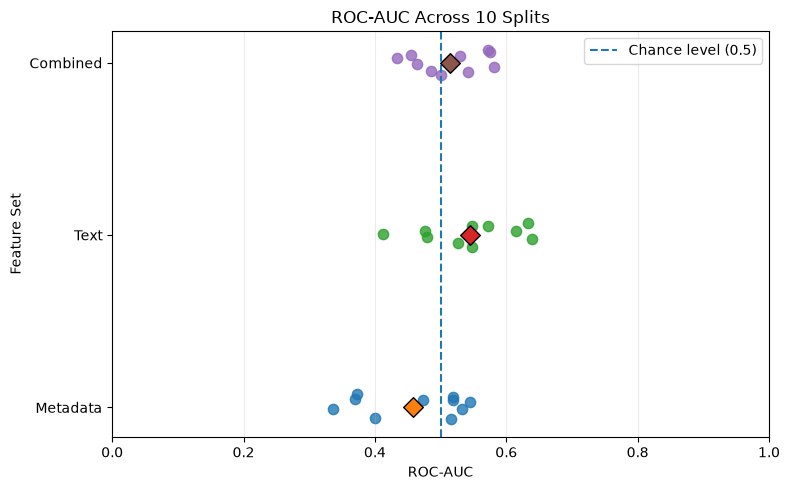

In [46]:

import matplotlib.pyplot as plt

# Order models for the figure
model_order = ["Metadata", "Text", "Combined"]

# Create the graph
fig, ax = plt.subplots(figsize=(8, 5))

# Make a random number genearator
random_generator = np.random.default_rng(42)

for y_position, model_name in enumerate(model_order):

    # Extract ROC-AUC from all splits
    roc_auc_values = results_all_models.loc[
        results_all_models["Model"] == model_name,
        "ROC-AUC"
    ].to_numpy()

    # Add random jitter to ensure points with overlapping values are visible
    jitter = random_generator.uniform(-0.08, 0.08, size=len(roc_auc_values))

    # Plot all points for the 10 splits
    ax.scatter(
        roc_auc_values,
        y_position + jitter,
        alpha=0.8,
        s=55
    )

    # Mark the ROC-AUC mean with a diamond
    ax.scatter(
        roc_auc_values.mean(),
        y_position,
        marker="D",
        s=100,
        edgecolors="black",
        zorder=3
    )

# Mark the random chance threshold (0.5)
ax.axvline(
    0.5,
    linestyle="--",
    linewidth=1.5,
    label=f"Chance level (0.5)"
)

# Set labels, grid and legend
ax.set_yticks(range(len(model_order)))
ax.set_yticklabels(model_order)
ax.set_xlabel("ROC-AUC")
ax.set_ylabel("Feature Set")
ax.set_title("ROC-AUC Across 10 Splits")
ax.set_xlim(0, 1)
ax.grid(axis="x", alpha=0.25)
ax.legend()

# Display graph
fig.tight_layout()
plt.show()


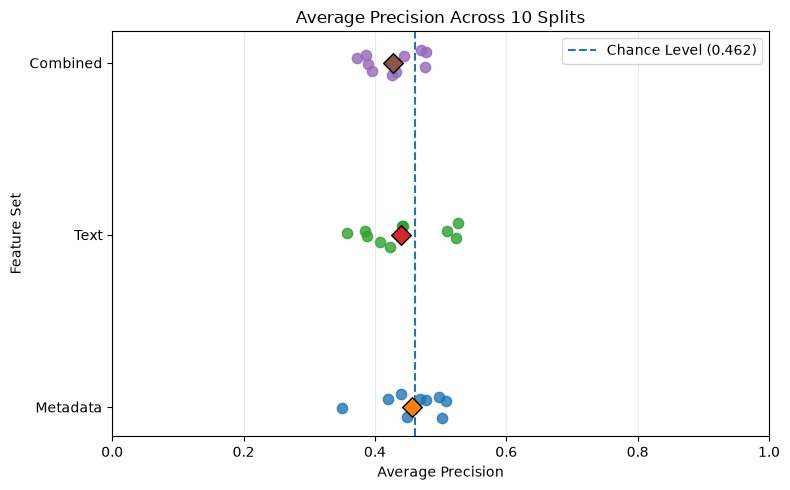

In [47]:

# Create the graph
fig, ax = plt.subplots(figsize=(8, 5))

# Make a random number genearator
random_generator = np.random.default_rng(42)

for y_position, model_name in enumerate(model_order):

    # Extract average precision values from all splits
    average_precision_values = results_all_models.loc[
        results_all_models["Model"] == model_name,
        "Average Precision"
    ].to_numpy()

    # Add random jitter to ensure points with overlapping values are visible
    jitter = random_generator.uniform(-0.08, 0.08, size=len(average_precision_values))

    # Plot all points for the 10 splits
    ax.scatter(
        average_precision_values,
        y_position + jitter,
        alpha=0.8,
        s=55
    )

    # Mark the average precision mean with a diamond
    ax.scatter(
        average_precision_values.mean(),
        y_position,
        marker="D",
        s=100,
        edgecolors="black",
        zorder=3
    )

# Calculate chance level with 18 POIs and 39 total
chance_level = 18 / 39

# Mark the random chance threshold
ax.axvline(
    chance_level,
    linestyle="--",
    linewidth=1.5,
    label=f"Chance Level ({chance_level:.3f})"
)

# Set labels, grid and legend
ax.set_yticks(range(len(model_order)))
ax.set_yticklabels(model_order)
ax.set_xlabel("Average Precision")
ax.set_ylabel("Feature Set")
ax.set_title("Average Precision Across 10 Splits")
ax.set_xlim(0, 1)
ax.grid(axis="x", alpha=0.25)
ax.legend()

# Display graph
fig.tight_layout()
plt.show()


## References for Code
- https://pandas.pydata.org/docs/reference/api/pandas.NA.html
- https://www.tutorialspoint.com/python_text_processing/python_extract_emails_from_text.htm
- https://pandas.pydata.org/pandas-docs/stable/reference/api/pandas.DataFrame.nunique.html?highlight=nunique
- https://pandas.pydata.org/docs/reference/api/pandas.Series.str.extract.html
- https://docs.python.org/3/library/re.html
- https://pandas.pydata.org/docs/reference/api/pandas.to_datetime.html
- https://pandas.pydata.org/docs/reference/api/pandas.Series.dt.tz_convert.html
- https://pandas.pydata.org/docs/reference/api/pandas.Series.dt.day_name.html
- https://numpy.org/doc/stable/reference/generated/numpy.log1p.html
- https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.reset_index.html
- https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.reset_index.html
- https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.train_test_split.html
- https://numpy.org/devdocs/reference/generated/numpy.concatenate.html
- https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.StandardScaler.html
- https://scikit-learn.org/stable/modules/generated/sklearn.impute.SimpleImputer.html
- https://scikit-learn.org/stable/modules/generated/sklearn.svm.OneClassSVM.html
- https://scikit-learn.org/stable/modules/generated/sklearn.metrics.roc_auc_score.html
- https://scikit-learn.org/stable/modules/generated/sklearn.metrics.average_precision_score.html
- https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.iloc.html
- https://scikit-learn.org/stable/modules/generated/sklearn.feature_extraction.text.TfidfVectorizer.html
- https://scikit-learn.org/stable/modules/generated/sklearn.decomposition.TruncatedSVD.html
- https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.loc.html
- https://numpy.org/doc/stable/reference/generated/numpy.hstack.html
- https://pandas.pydata.org/docs/reference/api/pandas.concat.html
- https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.agg.html
- https://matplotlib.org/3.5.3/api/_as_gen/matplotlib.pyplot.html
- https://numpy.org/doc/2.2/reference/random/generator.html